# C1_06_Workout_Type_Input
- X = X_flat_c1_v2.npy
- Y = y_labels_c1_v2.csv
- R1 = r1_whole_run_labels.csv (built by R1\Garmin_R1_WholeRun_FullArchive)

### Does adding the whole-run workout type (R1) as an input help? Random Forest, Simple DNN and GRU

R1 gives each run one of five workout types: `Z2/Steady State`, `Structured Intervals`, `Z2/Steady State with Strides`, `Tempo Run` and `Structured Intervals with Strides`. It is joined to the windows by `file_path`, one-hot encoded, and the same value is repeated for every window in that run.

**Baselines (without R1, VAL windows):**
- Random Forest: 0.567 (C1_01_Baselines)
- Simple DNN: 0.575 (C1_01_Baselines)
- GRU 64×3: 0.594 (C1_03_Architecture_Ablation)

The test set is not used.

## 1. Setup and configuration

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras

tf.random.set_seed(42)
np.random.seed(42)

DATA_DIR = Path(r"C:\dev\UoW\DATAX504\Final Assignment\garmin_data\Processed")

X_FLAT_PATH = DATA_DIR / "X_flat_c1_v2.npy"
Y_LABELS_PATH = DATA_DIR / "y_labels_c1_v2.csv"
R1_LABELS_PATH = DATA_DIR / "r1_whole_run_labels.csv"

R1_CATEGORIES = [
    "Z2/Steady State",
    "Structured Intervals",
    "Z2/Steady State with Strides",
    "Tempo Run",
    "Structured Intervals with Strides",
]


## 2. Load X, Y and R1, joined by file name

R1 is joined to the windows by `file_path`, because the R1 notebooks number the runs separately from `run_idx`. All 1,875 runs matched, so no windows are dropped.

In [2]:
X_flat = np.load(X_FLAT_PATH)
y_labels_df = pd.read_csv(Y_LABELS_PATH, parse_dates=["date"])
r1_df = pd.read_csv(R1_LABELS_PATH, parse_dates=["date"])

print(f"X_flat: {X_flat.shape}")
print(f"y_labels_df: {len(y_labels_df)} rows, {y_labels_df['file_path'].nunique()} unique files")
print(f"r1_df: {len(r1_df)} rows, {r1_df['file_path'].nunique()} unique files")

# Join by file_path only — run_idx differs between the two pipelines.
r1_lookup = r1_df.set_index("file_path")["r1_whole_run_label"]
y_labels_df["r1_whole_run_label"] = y_labels_df["file_path"].map(r1_lookup)

missing_r1 = y_labels_df["r1_whole_run_label"].isna().sum()
print(f"\nWindows with no matching R1 label (file not in r1_df): {missing_r1}")

# Drop any windows whose file didn't get an R1 label at all
keep_mask = y_labels_df["r1_whole_run_label"].notna().to_numpy()
X_flat = X_flat[keep_mask]
y_labels_df = y_labels_df[keep_mask].reset_index(drop=True)
print(f"After dropping unmatched windows: {len(y_labels_df)} windows, X_flat shape {X_flat.shape}")

print("\nR1 label counts (window-level, after broadcast):")
print(y_labels_df["r1_whole_run_label"].value_counts())


X_flat: (197341, 121)
y_labels_df: 197341 rows, 1875 unique files
r1_df: 1875 rows, 1875 unique files

Windows with no matching R1 label (file not in r1_df): 0
After dropping unmatched windows: 197341 windows, X_flat shape (197341, 121)

R1 label counts (window-level, after broadcast):
r1_whole_run_label
Z2/Steady State                      89866
Structured Intervals                 73229
Z2/Steady State with Strides         18977
Tempo Run                            14687
Structured Intervals with Strides      582
Name: count, dtype: int64


## 3. One-hot encode R1, append to X

Each of the five R1 types becomes its own 0/1 column, and the five columns are added to the end of X, so X goes from 121 to 126 columns. The same values repeat for every window in a run.

For example, a window from a `Tempo Run` gets `0, 0, 0, 1, 0` in the five columns, in the order `Z2/Steady State`, `Structured Intervals`, `Z2/Steady State with Strides`, `Tempo Run`, `Structured Intervals with Strides`.

In [3]:
r1_onehot = pd.get_dummies(
    pd.Categorical(y_labels_df["r1_whole_run_label"], categories=R1_CATEGORIES),
    prefix="r1",
).to_numpy(dtype=float)

print(f"R1 one-hot shape: {r1_onehot.shape}")

X_flat_with_r1 = np.concatenate([X_flat, r1_onehot], axis=1)
print(f"X_flat_with_r1 shape: {X_flat_with_r1.shape}  (was {X_flat.shape[1]}, +{r1_onehot.shape[1]} R1 columns)")


R1 one-hot shape: (197341, 5)
X_flat_with_r1 shape: (197341, 126)  (was 121, +5 R1 columns)


## 4. Split by run and encode the target

The split is the same as in the baselines (seed 42 at both levels), so the TRAIN and VAL windows are identical. The test runs are set aside and never built.

In [4]:
le = LabelEncoder()
y_encoded = le.fit_transform(y_labels_df["c1_target"])
print("Classes:", dict(zip(le.classes_, range(len(le.classes_)))))
n_classes = len(le.classes_)

run_idx_all = y_labels_df["run_idx"].to_numpy()
unique_runs = np.unique(run_idx_all)

train_runs, test_runs = train_test_split(unique_runs, test_size=0.2, random_state=42)
train_mask = np.isin(run_idx_all, train_runs)

X_trainval_raw = X_flat_with_r1[train_mask]
y_trainval = y_encoded[train_mask]

trainval_run_idx = run_idx_all[train_mask]
trainval_unique_runs = np.unique(trainval_run_idx)
fit_runs, val_runs = train_test_split(trainval_unique_runs, test_size=0.15, random_state=42)
fit_mask = np.isin(trainval_run_idx, fit_runs)
val_mask = np.isin(trainval_run_idx, val_runs)

X_train_raw, X_val_raw = X_trainval_raw[fit_mask], X_trainval_raw[val_mask]
y_train, y_val = y_trainval[fit_mask], y_trainval[val_mask]

print(f"Fit: {len(y_train)}, Val: {len(y_val)} (test set intentionally not built in this notebook)")


Classes: {'Base': 0, 'Declining': 1, 'Improving': 2, 'Recovery': 3}
Fit: 132966, Val: 24545 (test set intentionally not built in this notebook)


## 5. Random Forest with R1

200 trees with balanced class weights, on the 126 columns (121 sensor values plus the five R1 columns). It is the same Random Forest as in the baselines, which scored 0.567 without R1.

In [5]:
rf = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42)
rf.fit(X_train_raw, y_train)
rf_pred = rf.predict(X_val_raw)
rf_acc = accuracy_score(y_val, rf_pred)
print(f"Random Forest (with R1) validation accuracy: {rf_acc:.3f}  (baseline without R1: 0.567)")
print("\nRandom Forest classification report (validation):")
print(classification_report(y_val, rf_pred, labels=np.arange(n_classes), target_names=le.classes_, zero_division=0))

feature_group_names = (
    (["hr"] * 30) + (["speed"] * 30) + (["cadence"] * 30) + (["temperature"] * 30)
    + ["distance"] + (["r1"] * len(R1_CATEGORIES))
)
importance_by_field = pd.Series(rf.feature_importances_, index=feature_group_names).groupby(level=0).sum()
print("\nFeature importance (grouped by field, R1 combined into one group):")
print(importance_by_field.sort_values(ascending=False))


Random Forest (with R1) validation accuracy: 0.570  (baseline without R1: 0.567)

Random Forest classification report (validation):
              precision    recall  f1-score   support

        Base       0.57      0.54      0.56      9739
   Declining       0.58      0.58      0.58      7733
   Improving       0.55      0.58      0.56      6585
    Recovery       0.77      0.84      0.80       488

    accuracy                           0.57     24545
   macro avg       0.62      0.63      0.63     24545
weighted avg       0.57      0.57      0.57     24545


Feature importance (grouped by field, R1 combined into one group):
cadence        0.391831
speed          0.300902
hr             0.219960
temperature    0.068002
distance       0.013348
r1             0.005958
dtype: float64


## 6. Simple DNN with R1

The Simple DNN from the baselines (16 → 8 → softmax, dropout 0.2), with the same training settings (batch 64, up to 100 epochs, early stopping with patience 10), on the 126 scaled columns. It scored 0.575 without R1.

In [6]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_val_scaled = scaler.transform(X_val_raw)

model = keras.Sequential([
    keras.layers.Input(shape=(X_train_scaled.shape[1],)),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(8, activation="relu"),
    keras.layers.Dense(n_classes, activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.fit(
    X_train_scaled, y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100, batch_size=64, verbose=2,
    callbacks=[keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)],
)
dnn_pred = model.predict(X_val_scaled, verbose=0).argmax(axis=1)
dnn_acc = accuracy_score(y_val, dnn_pred)
print(f"Simple DNN (with R1) validation accuracy: {dnn_acc:.3f}  (baseline without R1: 0.574)")
print("\nSimple DNN classification report (validation):")
print(classification_report(y_val, dnn_pred, labels=np.arange(n_classes), target_names=le.classes_, zero_division=0))


Epoch 1/100
2078/2078 - 9s - 4ms/step - accuracy: 0.4976 - loss: 1.0541 - val_accuracy: 0.5471 - val_loss: 0.9738
Epoch 2/100
2078/2078 - 11s - 5ms/step - accuracy: 0.5377 - loss: 0.9805 - val_accuracy: 0.5539 - val_loss: 0.9610
Epoch 3/100
2078/2078 - 10s - 5ms/step - accuracy: 0.5475 - loss: 0.9684 - val_accuracy: 0.5613 - val_loss: 0.9471
Epoch 4/100
2078/2078 - 11s - 5ms/step - accuracy: 0.5532 - loss: 0.9593 - val_accuracy: 0.5658 - val_loss: 0.9380
Epoch 5/100
2078/2078 - 10s - 5ms/step - accuracy: 0.5572 - loss: 0.9547 - val_accuracy: 0.5705 - val_loss: 0.9340
Epoch 6/100
2078/2078 - 10s - 5ms/step - accuracy: 0.5590 - loss: 0.9506 - val_accuracy: 0.5696 - val_loss: 0.9305
Epoch 7/100
2078/2078 - 10s - 5ms/step - accuracy: 0.5597 - loss: 0.9491 - val_accuracy: 0.5684 - val_loss: 0.9322
Epoch 8/100
2078/2078 - 10s - 5ms/step - accuracy: 0.5598 - loss: 0.9467 - val_accuracy: 0.5685 - val_loss: 0.9288
Epoch 9/100
2078/2078 - 11s - 5ms/step - accuracy: 0.5612 - loss: 0.9452 - val_ac

## 7. GRU 64×3 with R1

The GRU 64×3 from the architecture sweep, which scored 0.594 without R1 (C1_03_Architecture_Ablation, same validation windows). 
R1's five columns are constant across a run, so they are not fed into the GRU as a time step. They are joined to the GRU's output, just before the final Dense layer.


Epoch 1/60
2078/2078 - 187s - 90ms/step - accuracy: 0.5258 - loss: 0.9843 - val_accuracy: 0.5685 - val_loss: 0.9306
Epoch 2/60
2078/2078 - 223s - 107ms/step - accuracy: 0.5650 - loss: 0.9370 - val_accuracy: 0.5751 - val_loss: 0.9163
Epoch 3/60
2078/2078 - 213s - 103ms/step - accuracy: 0.5703 - loss: 0.9284 - val_accuracy: 0.5763 - val_loss: 0.9107
Epoch 4/60
2078/2078 - 268s - 129ms/step - accuracy: 0.5734 - loss: 0.9219 - val_accuracy: 0.5818 - val_loss: 0.9051
Epoch 5/60
2078/2078 - 246s - 118ms/step - accuracy: 0.5760 - loss: 0.9181 - val_accuracy: 0.5835 - val_loss: 0.9018
Epoch 6/60
2078/2078 - 213s - 103ms/step - accuracy: 0.5783 - loss: 0.9140 - val_accuracy: 0.5846 - val_loss: 0.9006
Epoch 7/60
2078/2078 - 221s - 107ms/step - accuracy: 0.5789 - loss: 0.9115 - val_accuracy: 0.5857 - val_loss: 0.8961
Epoch 8/60
2078/2078 - 169s - 82ms/step - accuracy: 0.5808 - loss: 0.9094 - val_accuracy: 0.5862 - val_loss: 0.8956
Epoch 9/60
2078/2078 - 198s - 95ms/step - accuracy: 0.5805 - loss:

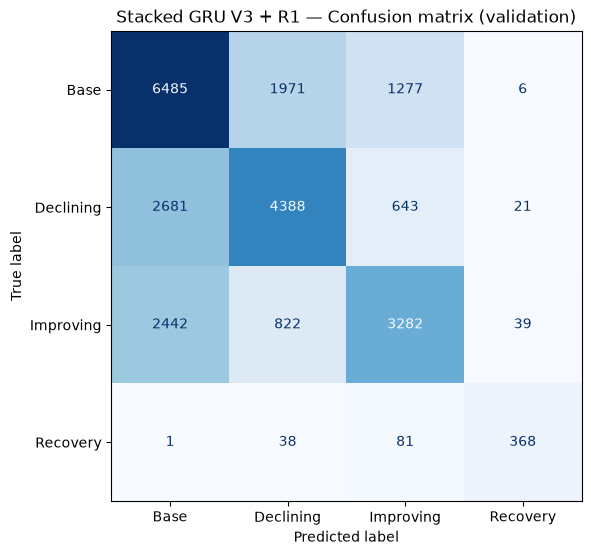

              precision    recall  f1-score   support

        Base       0.56      0.67      0.61      9739
   Declining       0.61      0.57      0.59      7733
   Improving       0.62      0.50      0.55      6585
    Recovery       0.85      0.75      0.80       488

    accuracy                           0.59     24545
   macro avg       0.66      0.62      0.64     24545
weighted avg       0.60      0.59      0.59     24545



In [7]:
X_hr = X_flat[:, 0:30]
X_speed = X_flat[:, 30:60]
X_cadence = X_flat[:, 60:90]
X_temp = X_flat[:, 90:120]
X_sequence = np.stack([X_hr, X_speed, X_cadence, X_temp], axis=-1)   # (n_windows, 30, 4)

X_seq_train_raw = X_sequence[train_mask][fit_mask]
X_seq_val_raw = X_sequence[train_mask][val_mask]

n_train_seq, timesteps, n_channels = X_seq_train_raw.shape
seq_scaler = StandardScaler()
X_seq_train = seq_scaler.fit_transform(X_seq_train_raw.reshape(-1, n_channels)).reshape(n_train_seq, timesteps, n_channels)
X_seq_val = seq_scaler.transform(X_seq_val_raw.reshape(-1, n_channels)).reshape(len(X_seq_val_raw), timesteps, n_channels)

# R1 one-hot, aligned to the same fit/val split
r1_train = r1_onehot[train_mask][fit_mask]
r1_val = r1_onehot[train_mask][val_mask]

seq_inputs = keras.layers.Input(shape=(timesteps, n_channels), name="sequence_input")
r1_inputs = keras.layers.Input(shape=(r1_onehot.shape[1],), name="r1_input")

x = keras.layers.GRU(64, recurrent_dropout=0.3, return_sequences=True)(seq_inputs)
x = keras.layers.GRU(64, recurrent_dropout=0.3, return_sequences=True)(x)
x = keras.layers.GRU(64, recurrent_dropout=0.3)(x)
x = keras.layers.Dropout(0.3)(x)

combined = keras.layers.Concatenate()([x, r1_inputs])
outputs = keras.layers.Dense(n_classes, activation="softmax")(combined)

model_gru_r1 = keras.Model(inputs=[seq_inputs, r1_inputs], outputs=outputs)
model_gru_r1.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

history_gru_r1 = model_gru_r1.fit(
    [X_seq_train, r1_train], y_train,
    validation_data=([X_seq_val, r1_val], y_val),
    epochs=60, batch_size=64, verbose=2,
    callbacks=[keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True)],
)

gru_r1_pred = model_gru_r1.predict([X_seq_val, r1_val], verbose=0).argmax(axis=1)
gru_r1_acc = accuracy_score(y_val, gru_r1_pred)
print(f"\nStacked GRU V3 (with R1) validation accuracy: {gru_r1_acc:.3f}  (baseline without R1: 0.598)")

cm = confusion_matrix(y_val, gru_r1_pred, labels=np.arange(n_classes))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Stacked GRU V3 + R1 — Confusion matrix (validation)")
plt.tight_layout()
plt.show()

print(classification_report(y_val, gru_r1_pred, labels=np.arange(n_classes), target_names=le.classes_, zero_division=0))


## 8. Summary: with R1 vs without

**Conclusion:** adding the whole-run workout type gave no meaningful gain. The Random Forest and DNN moved by 0.003 and 0.001, within noise, and the GRU was slightly lower. In the Random Forest, R1 carries only 0.6% of the feature importance. R1 was not used as a model input.

In [4]:
results = [
    ("Random Forest", 0.567, 0.570),
    ("Simple DNN",    0.575, 0.576),
    ("GRU 64x3",      0.594, 0.592),
]
print(f"{'Model':<30}{'Without R1':<15}{'With R1':<15}")
for name, without, with_r1 in results:
    print(f"{name:<30}{without:<15.3f}{with_r1:<15.3f}")


Model                         Without R1     With R1        
Random Forest                 0.567          0.570          
Simple DNN                    0.575          0.576          
GRU 64x3                      0.594          0.592          
